# Sentiment Analysis for Telugu, English and Telugu-English Code-Mixed Text — current state

**Classes:** `0 = Negative`, `1 = Neutral`, `2 = Positive`

This notebook **reads the project's saved, executed results** and demonstrates the served model. It does not train
anything. The authoritative pipeline lives in `D:\NLP\sentiment_app\backend\pipeline` (see `sentiment_app/README.md`).

- The original Phase-1 notebook (Telugu-only run, 30 Sep 2026) is preserved unchanged in
  `D:\NLP\archive\context_aware_sentiment_analysis_phase1_telugu_2026-09-30.ipynb`. Its results are in `D:\NLP\outputs` (read-only).
- **Model C (context-aware): Skipped — no real conversation_id/message_order available.** No dataset contains genuine
  conversation metadata, so genuine context-aware training was not performed. Every served prediction uses the current message only.
- Kernel: **Python (NLP Sentiment)** = Python 3.11 at `C:\Users\sresh\AppData\Local\Programs\Python\Python311\python.exe`.

## 1. Environment verification

In [1]:
import sys
print(sys.executable)

import joblib
import sklearn
import torch
import transformers
import datasets
import evaluate

print("joblib:", joblib.__version__)
print("sklearn:", sklearn.__version__)
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("datasets:", datasets.__version__)
print("evaluate:", evaluate.__version__)
print("CUDA:", torch.cuda.is_available())

import pandas, numpy, matplotlib, seaborn, scipy, accelerate, sentencepiece, tokenizers, openpyxl
for m in (pandas, numpy, matplotlib, seaborn, scipy, accelerate, sentencepiece, tokenizers, openpyxl):
    print(f"{m.__name__}: {getattr(m, '__version__', 'ok')}")

C:\Users\sresh\AppData\Local\Programs\Python\Python311\python.exe


C:\Users\sresh\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


joblib: 1.5.3
sklearn: 1.9.1
torch: 2.11.0+cpu
transformers: 5.17.0
datasets: 5.0.1
evaluate: 0.4.6
CUDA: False


pandas: 3.0.1
numpy: 2.4.3
matplotlib: 3.10.8
seaborn: 0.13.2
scipy: 1.17.1
accelerate: 1.15.0
sentencepiece: 0.2.2
tokenizers: 0.23.2
openpyxl: 3.1.5


In [2]:
import json, hashlib
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

NLP = Path(r"D:\NLP")
APP = NLP / "sentiment_app"
sys.path.insert(0, str(APP / "backend"))
MULTI = APP / "artifacts" / "multilingual"
DATA, EXP = MULTI / "data", MULTI / "experiments"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)

## 2. Data and split
TeSent (Telugu) + TweetEval sentiment (English) + CMTET (Telugu-English code-mixed). Label mappings are taken only from
each dataset's documentation (`label_mapping.json`). Hate-speech files in `Tel_Eng_dataset` are **not** used.
The split is a group-level stratified 70/15/15 split (identical cleaned texts never cross splits); the **test split is frozen**.

In [3]:
split = {s: pd.read_csv(DATA / f"{s}.csv", encoding="utf-8-sig", low_memory=False) for s in ("train", "validation", "test")}
print(json.dumps(json.loads((DATA / "label_mapping.json").read_text(encoding="utf-8"))["documented_mappings"], indent=1))
for s, d in split.items():
    print(f"\n{s}: {len(d):,} rows")
    display(pd.crosstab(d["language_type"], d["label"].map({0: "Negative", 1: "Neutral", 2: "Positive"}), margins=True))
pkg = APP / "artifacts" / "colab_package_phase3" / "MANIFEST.json"
if pkg.exists():
    man = json.loads(pkg.read_text())
    for s in split:
        ok = man[f"data/{s}.csv"] == hashlib.sha256((DATA / f"{s}.csv").read_bytes()).hexdigest()
        print(f"{s}.csv matches the Colab package fingerprint: {ok}")

{
 "TeSent": {
  "Negative": "Negative",
  "Neutral": "Neutral",
  "Positive": "Positive"
 },
 "TweetEval": {
  "0": "Negative",
  "1": "Neutral",
  "2": "Positive"
 },
 "CMTET": {
  "NEG": "Negative",
  "NTL": "Neutral",
  "POS": "Positive"
 }
}

train: 70,540 rows


label,Negative,Neutral,Positive,All
language_type,,,,
code_mixed,5383,2933,5530,13846
english,7963,19224,14725,41912
telugu,4100,6714,3968,14782
All,17446,28871,24223,70540



validation: 15,121 rows


label,Negative,Neutral,Positive,All
language_type,,,,
code_mixed,1157,629,1186,2972
english,1706,4119,3155,8980
telugu,879,1439,851,3169
All,3742,6187,5192,15121



test: 15,124 rows


label,Negative,Neutral,Positive,All
language_type,,,,
code_mixed,1156,632,1188,2976
english,1707,4119,3155,8981
telugu,878,1439,850,3167
All,3741,6190,5193,15124


train.csv matches the Colab package fingerprint: True
validation.csv matches the Colab package fingerprint: True
test.csv matches the Colab package fingerprint: True


## 3. Executed results (multilingual test split, n = 15,124)
Only models chosen on **validation** are scored on test. The Telugu-only run uses a different test split (n = 3,168) and is shown separately.

In [4]:
comp = pd.read_csv(EXP / "final_model_comparison.csv", encoding="utf-8-sig")
display(comp.round(4))
print("Telugu-only run (different test split, not comparable with the table above):")
display(pd.read_csv(EXP / "recomputed_metrics_comparison.csv", encoding="utf-8-sig")
        .query("model.str.startswith('Telugu')", engine="python")
        [["model", "n", "accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1", "Negative_f1", "Neutral_f1", "Positive_f1"]].round(4))

,Model,Input,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative Precision,Negative Recall,Negative F1,Negative Support,Neutral Precision,Neutral Recall,Neutral F1,Neutral Support,Positive Precision,Positive Recall,Positive F1,Positive Support,English Accuracy,English Macro F1,Telugu Accuracy,Telugu Macro F1,Code-mixed Accuracy,Code-mixed Macro F1,English Negative F1,English Neutral F1,English Positive F1,Telugu Negative F1,Telugu Neutral F1,Telugu Positive F1,Code-mixed Negative F1,Code-mixed Neutral F1,Code-mixed Positive F1,As-served Macro F1 (detected language),ECE (test),Best Validation Macro F1,Notes
0,Multilingual A,cleaned_text,0.6635,0.6624,0.6662,0.6637,0.6653,0.6635,0.6639,0.6224,0.6784,0.6492,3741.0,0.6488,0.6426,0.6457,6190.0,0.7160,0.6776,0.6963,5193.0,0.6405,0.6281,0.6085,0.6008,0.7917,0.7660,0.5607,0.6472,0.6764,0.5660,0.6432,0.5933,0.8407,0.6421,0.8152,0.6637,0.0267,0.6609,"Word TF-IDF (1,2) 20k + LogisticRegression balanced (original baseline)"
1,Multilingual A+,cleaned_text,0.6994,0.6995,0.7010,0.7001,0.7002,0.6994,0.6996,0.6792,0.7068,0.6927,3741.0,0.6800,0.6850,0.6825,6190.0,0.7394,0.7113,0.7251,5193.0,0.6734,0.6617,0.6767,0.6710,0.8021,0.7774,0.6010,0.6808,0.7033,0.6545,0.6992,0.6594,0.8530,0.6528,0.8265,0.7001,0.0110,0.6962,"Word (1,2) 20k + char_wb (3,5) TF-IDF + LogisticRegression balanced"
2,Best alternative Transformer (multilingual-e5-small),cleaned_text,0.7445,0.7513,0.7416,0.7458,0.7465,0.7445,0.7449,0.7688,0.7172,0.7421,3741.0,0.7029,0.7502,0.7258,6190.0,0.7824,0.7574,0.7697,5193.0,0.7366,0.7297,0.7155,0.7123,0.7994,0.7801,0.6920,0.7349,0.7621,0.6988,0.7279,0.7102,0.8486,0.6626,0.8291,0.7458,0.0340,0.7431,"intfloat/multilingual-e5-small, lr 3e-05, loss ce, label smoothing 0, wd 0.0..."
3,Ensemble (validation-tuned weights),cleaned_text (all members),0.7510,0.7575,0.7484,0.7524,0.7528,0.7510,0.7514,0.7738,0.7271,0.7497,3741.0,0.7107,0.7561,0.7327,6190.0,0.7878,0.7622,0.7748,5193.0,0.7418,0.7350,0.7231,0.7197,0.8085,0.7892,0.6979,0.7408,0.7663,0.7054,0.7360,0.7179,0.8592,0.6733,0.8352,0.7524,0.0103,0.7486,"weights Multilingual A+ 0.20, Best alternative Transformer (multilingual-e5-..."
4,Language-aware ensemble (validation-tuned weights),cleaned_text (all members),0.7536,0.7595,0.7520,0.7553,0.7554,0.7536,0.7540,0.7705,0.7394,0.7546,3741.0,0.7134,0.7578,0.7349,6190.0,0.7947,0.7587,0.7763,5193.0,0.7418,0.7350,0.7300,0.7259,0.8142,0.7929,0.6979,0.7408,0.7663,0.7128,0.7452,0.7196,0.8673,0.6719,0.8394,0.7545,0.0165,0.7501,"English: Multilingual A+ 0.20, Best alternative Transformer (multilingual-e5..."
5,Current production ensemble (A+ 0.50 / E5 0.50),cleaned_text (all members),0.7483,0.7534,0.7470,0.7499,0.7498,0.7483,0.7486,0.7625,0.7362,0.7491,3741.0,0.7112,0.7501,0.7301,6190.0,0.7865,0.7549,0.7704,5193.0,0.7339,0.7271,0.7278,0.7242,0.8135,0.7929,0.6903,0.7345,0.7564,0.7094,0.7417,0.7214,0.8646,0.6744,0.8396,0.7499,0.0332,0.7463,"frozen production ensemble: Multilingual A+ 0.50, Best alternative Transform..."
6,Best improved classical model,cleaned_text,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Best of 177 validation-searched classical configs: s0_a_plus_reproduced (val...
7,Multilingual XLM-R Model B,cleaned_text,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not trained / pending GPU run.
8,Model C (context-aware),context_text,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Skipped — no real conversation_id/message_order available. True context-awar...


Telugu-only run (different test split, not comparable with the table above):


,model,n,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,Negative_f1,Neutral_f1,Positive_f1
2,Telugu A,3168,0.6285,0.6223,0.6252,0.6232,0.6287,0.6151,0.653,0.6016
3,Telugu B,3168,0.6979,0.6959,0.7018,0.6985,0.6979,0.6999,0.695,0.7005


In [5]:
lb = pd.read_csv(EXP / "experiment_leaderboard.csv", encoding="utf-8-sig")
cls = lb[lb["experiment_id"].str.match(r"s[0-6]_")]
print(f"Classical validation-only search: {len(cls)} configurations (word / char / union TF-IDF, LR / LinearSVC / SGD, "
      "preprocessing variants, signal features). Top 10 by validation macro F1:")
display(cls.sort_values("validation_macro_f1", ascending=False).head(10)
        [["experiment_id", "model", "validation_accuracy", "validation_macro_precision", "validation_macro_recall", "validation_macro_f1"]].round(4))

Classical validation-only search: 177 configurations (word / char / union TF-IDF, LR / LinearSVC / SGD, preprocessing variants, signal features). Top 10 by validation macro F1:


,experiment_id,model,validation_accuracy,validation_macro_precision,validation_macro_recall,validation_macro_f1
12,s0_a_plus_reproduced,LogisticRegression,0.6964,0.6967,0.6976,0.6969
13,s4_lr_bal_C1,LogisticRegression,0.6964,0.6967,0.6975,0.6969
14,s5_v3_repeat_norm,LogisticRegression,0.6963,0.6967,0.6974,0.6968
15,s5_v4b_emoticons_only,LogisticRegression,0.6963,0.6965,0.6975,0.6968
16,s6_signals_w1,LogisticRegression,0.6966,0.6967,0.6972,0.6968
17,s5_v4_repeat_norm_emoticons,LogisticRegression,0.6963,0.6968,0.6972,0.6967
18,s4_sgd_modified_huber_a0.0001,SGDClassifier,0.6972,0.7006,0.6937,0.6967
19,s4_sgd_log_loss_a1e-05,SGDClassifier,0.6973,0.7009,0.6934,0.6966
20,s6_signals_w0.3,LogisticRegression,0.6964,0.6964,0.6970,0.6965
21,s2_char_ng35_md2_f80k,LogisticRegression,0.6959,0.6960,0.6973,0.6962


## 4. Transformer experiments (Colab GPU)

In [6]:
trans = EXP / "transformers"
runs = sorted(trans.glob("*/validation_metrics.json")) if trans.exists() else []
if not runs:
    display(Markdown("**No Transformer results imported yet — Not trained / pending GPU run.**  \n"
                     "Run `sentiment_app/artifacts/colab_package_phase3/colab_phase3_transformers.ipynb` on a Colab GPU "
                     "(upload `transformer_package.zip`), copy `phase3_results_*.zip` to `sentiment_app/artifacts/colab_results/`, then run "
                     "`python -m pipeline.finalize_phase3 --import` in `sentiment_app/backend`. See `sentiment_app/docs/COLAB_PHASE3.md`."))
else:
    rows = []
    for f in runs:
        v, c = json.loads(f.read_text()), json.loads((f.parent / "config.json").read_text())
        rows.append({"experiment": f.parent.name, "model": c["model"], "val_acc": v["accuracy"], "val_macro_P": v["macro_precision"],
                     "val_macro_R": v["macro_recall"], "val_macro_F1": v["macro_f1"], "val_weighted_F1": v["weighted_f1"],
                     **{f"val_{k}_F1": v["per_class"][k]["f1"] for k in ("Negative", "Neutral", "Positive")},
                     "best_epoch": c.get("best_epoch"), "tested": (f.parent / "test_metrics.json").exists()})
    display(pd.DataFrame(rows).sort_values(["val_macro_F1", "val_macro_R", "val_acc"], ascending=False).round(4))

,experiment,model,val_acc,val_macro_P,val_macro_R,val_macro_F1,val_weighted_F1,val_Negative_F1,val_Neutral_F1,val_Positive_F1,best_epoch,tested
2,indicbert_lr2e-05_ce_ep3p2_bs16x1_wd0.01_wu0.1_len128,ai4bharat/IndicBERTv2-MLM-only,0.7485,0.7496,0.7515,0.7505,0.7482,0.7526,0.7195,0.7793,3.0,False
8,xlmr_lr1e-05_ce_ep3p2_bs16x1_wd0.01_wu0.1_len128,xlm-roberta-base,0.7478,0.7512,0.7478,0.7488,0.7484,0.7412,0.7302,0.7752,2.0,False
3,indicbert_lr2e-05_ce_ep4p2_bs16x1_wd0.01_wu0.1_len128,ai4bharat/IndicBERTv2-MLM-only,0.7467,0.7475,0.7506,0.7488,0.7463,0.7537,0.7168,0.7760,3.0,False
4,indicbert_lr3e-05_ce_ep3p2_bs16x1_wd0.01_wu0.1_len128,ai4bharat/IndicBERTv2-MLM-only,0.7460,0.7479,0.7485,0.7480,0.7463,0.7479,0.7230,0.7730,2.0,False
9,xlmr_lr2e-05_ce_ep3p2_bs16x1_wd0.01_wu0.1_len128,xlm-roberta-base,0.7437,0.7467,0.7435,0.7448,0.7442,0.7370,0.7236,0.7739,2.0,False
0,e5_lr3e-05_ce_ep3p2_bs32_len128_cpu,intfloat/multilingual-e5-small,0.7420,0.7484,0.7390,0.7431,0.7423,0.7379,0.7233,0.7682,2.0,True
10,xlmr_lr3e-05_ce_ep3p2_bs16x1_wd0.01_wu0.1_len128,xlm-roberta-base,0.7412,0.7405,0.7458,0.7427,0.7405,0.7427,0.7092,0.7762,3.0,False
6,muril_lr3e-05_ce_ep3p2_bs16x1_wd0.01_wu0.1_len128,google/muril-base-cased,0.7395,0.7423,0.7410,0.7414,0.7391,0.7432,0.7098,0.7711,3.0,False
5,muril_lr2e-05_ce_ep3p2_bs16x1_wd0.01_wu0.1_len128,google/muril-base-cased,0.7399,0.7413,0.7408,0.7408,0.7403,0.7331,0.7212,0.7681,2.0,False
1,e5_lr5e-05_ce_ep3p2_bs32_len128_cpu,intfloat/multilingual-e5-small,0.7378,0.7434,0.7354,0.7390,0.7381,0.7323,0.7157,0.7690,2.0,True


## 5. Error analysis, statistics and calibration

Model A+ test errors by class pair:


,error_pair,count,share_of_errors
0,Negative -> Neutral,822,0.1808
1,Negative -> Positive,275,0.0605
2,Neutral -> Negative,923,0.2030
3,Neutral -> Positive,1027,0.2259
4,Positive -> Negative,326,0.0717
5,Positive -> Neutral,1173,0.2580


By language:


,language_type,n,errors,error_rate,accuracy,share_of_all_errors
0,code_mixed,2976,589,0.1979,0.8021,0.1296
1,english,8981,2933,0.3266,0.6734,0.6452
2,telugu,3167,1024,0.3233,0.6767,0.2253


Accuracy by confidence bucket:


,confidence_bucket,n,errors,error_rate,accuracy,share_of_all_errors
0,0.00-0.50,2386,1297,0.5436,0.4564,0.2853
1,0.50-0.60,3017,1293,0.4286,0.5714,0.2844
2,0.60-0.70,2684,917,0.3417,0.6583,0.2017
3,0.70-0.80,2480,596,0.2403,0.7597,0.1311
4,0.80-0.90,2151,343,0.1595,0.8405,0.0755
5,0.90-1.00,2406,100,0.0416,0.9584,0.0220


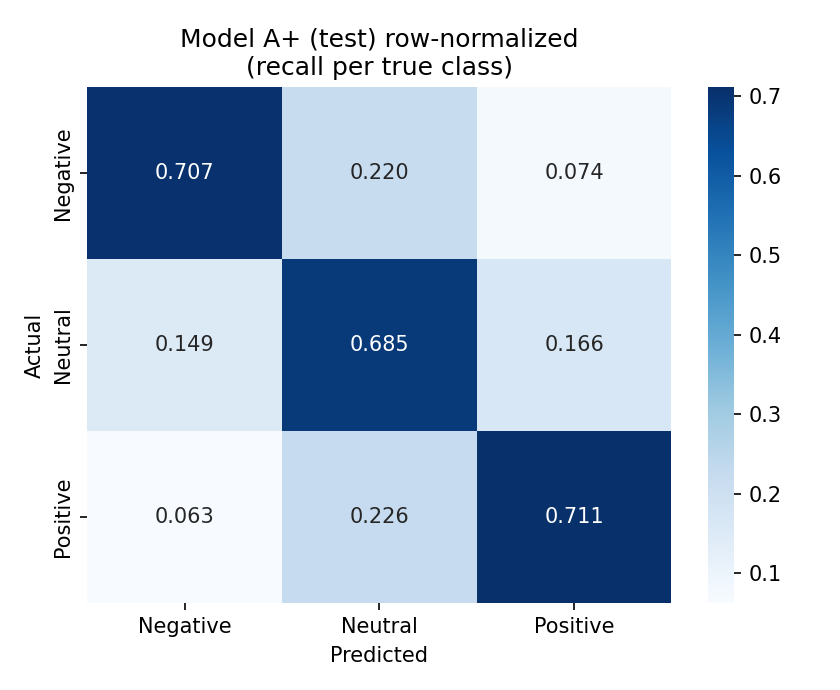

Multilingual A vs Multilingual A+: McNemar p = 5.33e-37; macro F1 difference -0.0364 (95% CI -0.0416 to -0.0310)
Best alternative Transformer (multilingual-e5-small) vs Multilingual A+: McNemar p = 4.2e-33; macro F1 difference +0.0458 (95% CI +0.0384 to +0.0531)
Ensemble (validation-tuned weights) vs Multilingual A+: McNemar p = 2.52e-48; macro F1 difference +0.0523 (95% CI +0.0452 to +0.0592)
Language-aware ensemble (validation-tuned weights) vs Multilingual A+: McNemar p = 2.26e-58; macro F1 difference +0.0552 (95% CI +0.0485 to +0.0617)
Current production ensemble (A+ 0.50 / E5 0.50) vs Multilingual A+: McNemar p = 4.35e-59; macro F1 difference +0.0498 (95% CI +0.0440 to +0.0557)
Ensemble vs Best alternative Transformer (multilingual-e5-small): McNemar p = 1.18e-05; macro F1 difference +0.0065 (95% CI +0.0036 to +0.0094)
Multilingual A+ vs Current production ensemble (A+ 0.50 / E5 0.50): McNemar p = 4.35e-59; macro F1 difference -0.0498 (95% CI -0.0557 to -0.0440)
Best alternative T

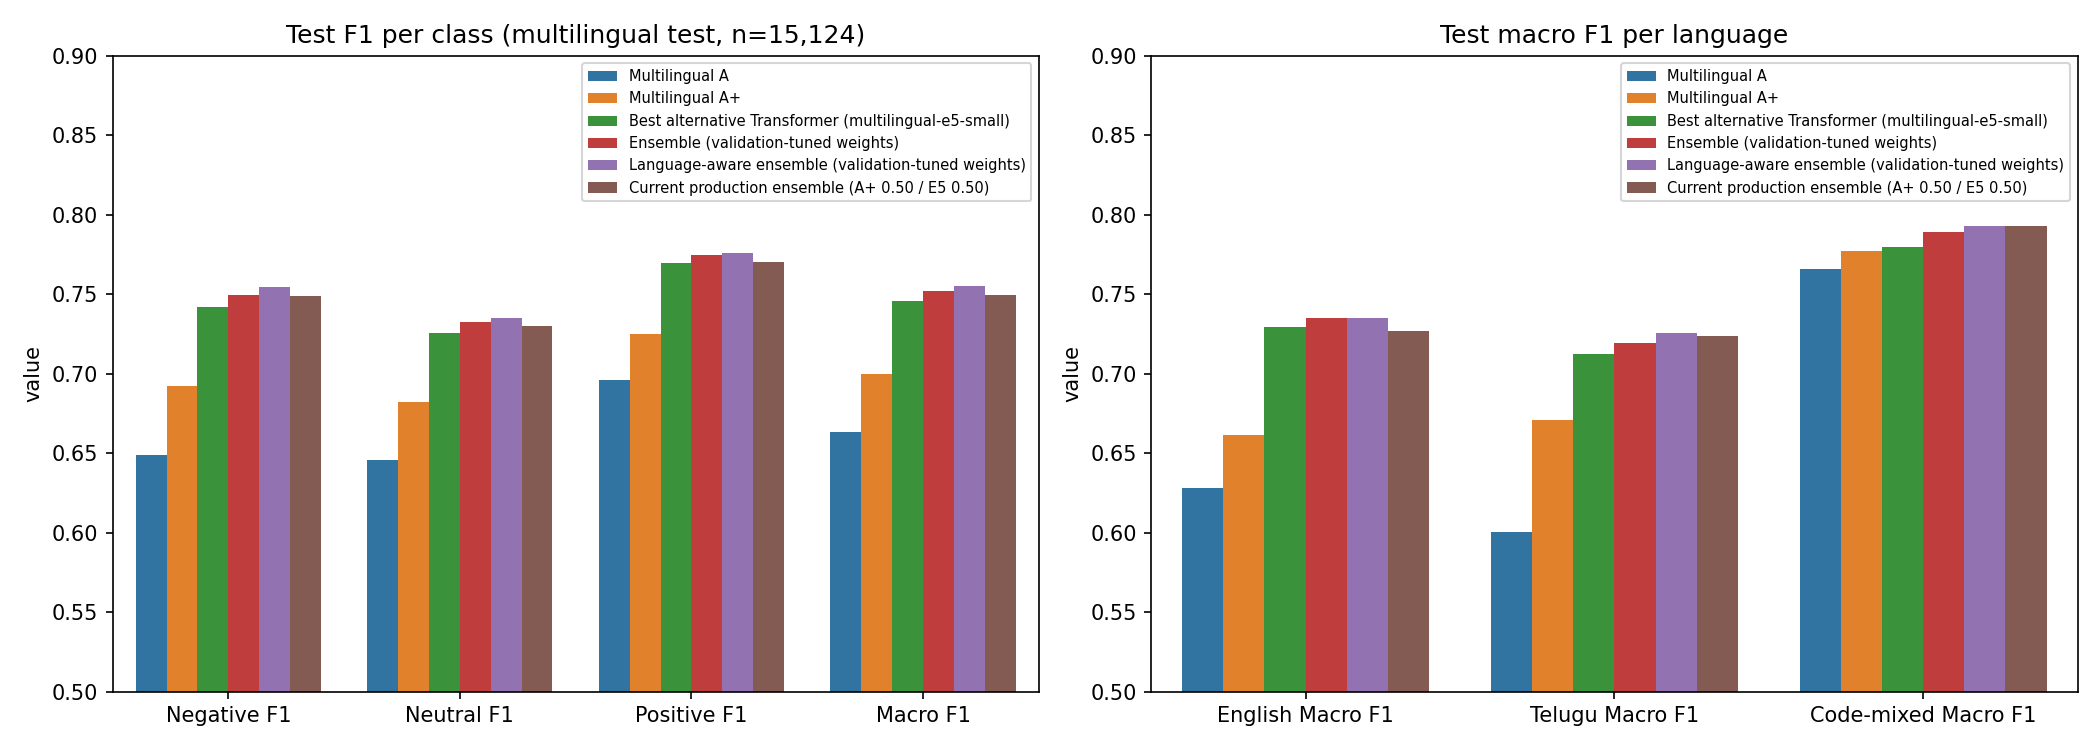

In [7]:
ea = EXP / "error_analysis_model_a_plus"
print("Model A+ test errors by class pair:"); display(pd.read_csv(ea / "class_pair_errors.csv"))
print("By language:"); display(pd.read_csv(ea / "errors_by_language.csv").iloc[:, :6])
print("Accuracy by confidence bucket:"); display(pd.read_csv(ea / "errors_by_confidence.csv"))
display(Image(filename=str(ea / "confusion_matrix_normalized.png"), width=420))
stats = json.loads((EXP / "statistical_comparison.json").read_text())
for k, v in stats.items():
    mc, bs = v["mcnemar"], v["bootstrap"]
    print(f"{k}: McNemar p = {mc['p_value']:.3g}; macro F1 difference {bs['macro_f1_diff_mean']:+.4f} "
          f"(95% CI {bs['macro_f1_diff_ci95'][0]:+.4f} to {bs['macro_f1_diff_ci95'][1]:+.4f})")
for d in sorted((EXP / "final").iterdir()):
    tm = d / "test_metrics.json"
    if tm.exists():
        cal = json.loads(tm.read_text())["calibration_test"]
        print(f"{d.name}: ECE {cal['ece_10_bins']:.4f}, mean confidence {cal['mean_confidence']:.4f}")
if (EXP / "final_model_comparison.png").exists():
    display(Image(filename=str(EXP / "final_model_comparison.png"), width=900))

## 6. Demonstration with the served model
Uses the web app's own `ModelService`: the final selected model if its files are on this machine, otherwise **Multilingual A+**.
The language shown is a heuristic guess; predictions use the current message only.

In [8]:
from app.config import settings
from app.model_service import ModelService
svc = ModelService(settings)
print("Serving:", svc.info(svc.default_id)["name"]); print(svc.selection_note())
examples = ["ఈ సినిమా చాలా బాగుంది 👍", "The delivery was late again. Not happy.", "The meeting is scheduled for 3 pm tomorrow.",
            "movie asalu bagaledu, time waste", "Service super ga undi bro, thank you!", "This is not bad at all", "😡😡"]
probs, cleaned, mid, langs = svc.predict_full(examples)
names = svc.class_names()
display(pd.DataFrame({"text": examples, "language (heuristic)": langs, "prediction": [names[i] for i in probs.argmax(1)],
                      "confidence": probs.max(1).round(3), **{f"P({c})": probs[:, i].round(3) for i, c in enumerate(names)},
                      "low_confidence (<0.5)": probs.max(1) < 0.5}))

Serving: Current production ensemble (A+ 0.50 / E5 0.50)
Final selected model: Current production ensemble (A+ 0.50 / E5 0.50).


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 2719.33it/s]

,text,language (heuristic),prediction,confidence,P(Negative),P(Neutral),P(Positive),low_confidence (<0.5)
0,ఈ సినిమా చాలా బాగుంది 👍,telugu,Positive,0.986,0.003,0.011,0.986,False
1,The delivery was late again. Not happy.,english,Negative,0.849,0.849,0.084,0.067,False
2,The meeting is scheduled for 3 pm tomorrow.,english,Neutral,0.809,0.088,0.809,0.102,False
3,"movie asalu bagaledu, time waste",code_mixed,Negative,0.972,0.972,0.017,0.011,False
4,"Service super ga undi bro, thank you!",code_mixed,Positive,0.985,0.004,0.012,0.985,False
5,This is not bad at all,english,Negative,0.508,0.508,0.081,0.411,False
6,😡😡,unknown,Negative,0.585,0.585,0.344,0.071,False


## 7. Methodology notes
- **TF-IDF + Logistic Regression (A):** word 1–2-grams weighted by TF-IDF, linear classifier with `class_weight="balanced"`.
- **A+:** adds character n-grams (`char_wb` 3–5), which handle Telugu morphology, Romanized spelling variation and code-switching. It is the best of 177 validation-searched classical configurations.
- **XLM-RoBERTa / MuRIL (Phase 3, Colab):** pretrained multilingual Transformers fine-tuned on `cleaned_text` (current message only), selected by validation macro F1 (ties: macro recall, then accuracy).
- **Selection rule:** train → fit; validation → choose model, hyperparameters, ensemble weights, temperature; test → evaluated once per selected model.
- **Metrics:** Macro F1 weights Negative/Neutral/Positive equally (primary); weighted F1 accounts for class frequency; accuracy = share of correct predictions.
- **Model C:** the context builder (`sentiment_core/context.py`, format `[PREVIOUS_2] … [PREVIOUS_1] … [CURRENT] …`, earlier messages only) and `train_transformer.py --input-col context_text` are ready, but training is refused until a real `conversations.csv` with `conversation_id` and `message_order` exists.